(1) Pengujian pada data evaluasi
Ketentuan :
- Confidence >< 0.10, 0.20, 0.30, 0.40, 0.50, 0.60
- NMS IoU >< 0.70
- Matching IoU >< 0.50
Tujuan : menentukan peforma maksimal pada saat nilai confidence berapa

In [3]:
# Import Library
import os
import csv
import time
import numpy as np
import pandas as pd

from pathlib import Path
from ultralytics import YOLO

print("Seluruh library berhasil diimpor.")

Seluruh library berhasil diimpor.


In [4]:
# Konfigurasi Pengujian
MODEL_PATH = "/home/rzangef/spark-data/yolo11_runs/yolo11s_40epochs/weights/best.pt"

IMAGE_DIR = Path("/home/rzangef/spark-data/CHVG-YOLO/images/val")
LABEL_DIR = Path("/home/rzangef/spark-data/CHVG-YOLO/labels/val")

IMG_SIZE = 640
NMS_IOU = 0.70
MATCH_IOU = 0.50

CONF_THRESHOLDS = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]

CLASS_NAMES = [
    "person", "vest", "yellow", "white",
    "glass", "blue", "red", "head"
]

OUTPUT_DIR = Path(
    "/home/rzangef/spark-data/yolo11_threshold_results"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Konfigurasi pengujian berhasil ditetapkan.")

Konfigurasi pengujian berhasil ditetapkan.


In [5]:
# Cek file dan dataset
# Memeriksa checkpoint
assert Path(MODEL_PATH).is_file(), "best.pt tidak ditemukan!"

# Memeriksa folder dataset
assert IMAGE_DIR.is_dir(), "Folder validation images tidak ditemukan!"
assert LABEL_DIR.is_dir(), "Folder validation labels tidak ditemukan!"

# Menghitung gambar
image_extensions = {".jpg", ".jpeg", ".png"}

images = sorted([
    p for p in IMAGE_DIR.rglob("*")
    if p.suffix.lower() in image_extensions
])

print("Jumlah gambar validation:", len(images))
print("Checkpoint tersedia:", Path(MODEL_PATH).is_file())
print("Folder anotasi tersedia:", LABEL_DIR.is_dir())

assert len(images) == 170, "Jumlah gambar bukan 170!"

print("\nPengecekan berhasil.")

Jumlah gambar validation: 170
Checkpoint tersedia: True
Folder anotasi tersedia: True

Pengecekan berhasil.


In [6]:
# Memuat Model
model = YOLO(MODEL_PATH)

print("Model YOLOv11 berhasil dimuat.")
print("Model:", MODEL_PATH)
print("Image size:", IMG_SIZE)
print("NMS IoU:", NMS_IOU)
print("Matching IoU:", MATCH_IOU)

Model YOLOv11 berhasil dimuat.
Model: /home/rzangef/spark-data/yolo11_runs/yolo11s_40epochs/weights/best.pt
Image size: 640
NMS IoU: 0.7
Matching IoU: 0.5


In [7]:
# Menyiapkan fungsi IoU dan evaluasi
def calculate_iou(box1, boxes2):

    if len(boxes2) == 0:
        return np.array([])

    x1 = np.maximum(box1[0], boxes2[:, 0])
    y1 = np.maximum(box1[1], boxes2[:, 1])
    x2 = np.minimum(box1[2], boxes2[:, 2])
    y2 = np.minimum(box1[3], boxes2[:, 3])

    intersection = (
        np.maximum(0, x2 - x1) *
        np.maximum(0, y2 - y1)
    )

    area1 = (
        (box1[2] - box1[0]) *
        (box1[3] - box1[1])
    )

    area2 = (
        (boxes2[:, 2] - boxes2[:, 0]) *
        (boxes2[:, 3] - boxes2[:, 1])
    )

    union = area1 + area2 - intersection

    return intersection / np.maximum(union, 1e-9)


print("Fungsi IoU berhasil dibuat.")

Fungsi IoU berhasil dibuat.


In [8]:
# Fungsi untuk membaca ground truth
def load_ground_truth(label_path, height, width):

    if not label_path.is_file():
        raise FileNotFoundError(
            f"Anotasi tidak ditemukan: {label_path}"
        )

    boxes = []
    classes = []

    with open(label_path, "r") as file:
        for line in file:

            values = line.strip().split()

            if not values:
                continue

            cls, xc, yc, bw, bh = map(float, values)

            x1 = (xc - bw / 2) * width
            y1 = (yc - bh / 2) * height
            x2 = (xc + bw / 2) * width
            y2 = (yc + bh / 2) * height

            boxes.append([x1, y1, x2, y2])
            classes.append(int(cls))

    return (
        np.array(boxes, dtype=float).reshape(-1, 4),
        np.array(classes, dtype=int)
    )


print("Fungsi pembacaan anotasi berhasil dibuat.")

Fungsi pembacaan anotasi berhasil dibuat.


In [10]:
# Fungsi calculate_metrics_for_image()
def calculate_metrics_for_image(pred_boxes, pred_classes, pred_scores,
                                gt_boxes, gt_classes, match_iou):

    tp, fp, fn = 0, 0, 0
    matched_gt = set()

    # Urutkan prediksi berdasarkan confidence tertinggi
    order = np.argsort(-pred_scores)

    for pred_idx in order:
        pred_box = pred_boxes[pred_idx]
        pred_class = pred_classes[pred_idx]

        # Cari ground truth dengan kelas sama
        candidates = [
            i for i, cls in enumerate(gt_classes)
            if cls == pred_class and i not in matched_gt
        ]

        if not candidates:
            fp += 1
            continue

        ious = calculate_iou(
            pred_box,
            gt_boxes[candidates]
        )

        best_position = np.argmax(ious)
        best_iou = ious[best_position]
        best_gt_idx = candidates[best_position]

        if best_iou >= match_iou:
            tp += 1
            matched_gt.add(best_gt_idx)
        else:
            fp += 1

    fn = len(gt_boxes) - len(matched_gt)

    return tp, fp, fn


print("Fungsi calculate_metrics_for_image berhasil didefinisikan.")

Fungsi calculate_metrics_for_image berhasil didefinisikan.


In [11]:
# Evaluasi

all_metrics = []
total_start_time = time.perf_counter()

for conf in CONF_THRESHOLDS:

    threshold_start_time = time.perf_counter()

    print(f"\nMemproses confidence threshold {conf:.2f}")

    total_tp = 0
    total_fp = 0
    total_fn = 0

    for image_path in images:

        result = model.predict(
            source=str(image_path),
            imgsz=IMG_SIZE,
            conf=conf,
            iou=NMS_IOU,
            device="cpu",
            verbose=False
        )[0]

        # Baca ground truth
        label_path = (
            LABEL_DIR / image_path.relative_to(IMAGE_DIR)
        ).with_suffix(".txt")

        height, width = result.orig_shape

        gt_boxes, gt_classes = load_ground_truth(
            label_path, height, width
        )

        # Ambil prediksi
        if result.boxes is not None and len(result.boxes) > 0:
            pred_boxes = result.boxes.xyxy.cpu().numpy()
            pred_classes = result.boxes.cls.cpu().numpy().astype(int)
            pred_scores = result.boxes.conf.cpu().numpy()
        else:
            pred_boxes = np.empty((0, 4))
            pred_classes = np.array([], dtype=int)
            pred_scores = np.array([], dtype=float)

        tp, fp, fn = calculate_metrics_for_image(
            pred_boxes,
            pred_classes,
            pred_scores,
            gt_boxes,
            gt_classes,
            MATCH_IOU
        )

        total_tp += tp
        total_fp += fp
        total_fn += fn

    precision = (
        total_tp / (total_tp + total_fp)
        if total_tp + total_fp > 0 else 0
    )

    recall = (
        total_tp / (total_tp + total_fn)
        if total_tp + total_fn > 0 else 0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    threshold_time = time.perf_counter() - threshold_start_time

    all_metrics.append({
        "Confidence": conf,
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn,
        "Precision (%)": precision * 100,
        "Recall (%)": recall * 100,
        "F1-score (%)": f1 * 100,
        "Waktu (detik)": threshold_time
    })

    print(f"Waktu pengujian: {threshold_time:.2f} detik")

total_time = time.perf_counter() - total_start_time

# Tampilkan hasil
df_results = pd.DataFrame(all_metrics)

print("\n=== HASIL PENGUJIAN YOLOv11 ===")
display(df_results.round(2))

print(f"\nTotal waktu seluruh pengujian: {total_time:.2f} detik")
print(f"Total waktu seluruh pengujian: {total_time / 60:.2f} menit")


Memproses confidence threshold 0.10
Waktu pengujian: 53.91 detik

Memproses confidence threshold 0.20
Waktu pengujian: 53.79 detik

Memproses confidence threshold 0.30
Waktu pengujian: 51.94 detik

Memproses confidence threshold 0.40
Waktu pengujian: 52.36 detik

Memproses confidence threshold 0.50
Waktu pengujian: 53.42 detik

Memproses confidence threshold 0.60
Waktu pengujian: 52.10 detik

=== HASIL PENGUJIAN YOLOv11 ===


,Confidence,TP,FP,FN,Precision (%),Recall (%),F1-score (%),Waktu (detik)
0,0.1,1083,374,128,74.33,89.43,81.18,53.91
1,0.2,1061,228,150,82.31,87.61,84.88,53.79
2,0.3,1030,153,181,87.07,85.05,86.05,51.94
3,0.4,1000,95,211,91.32,82.58,86.73,52.36
4,0.5,943,63,268,93.74,77.87,85.07,53.42
5,0.6,849,34,362,96.15,70.11,81.09,52.10



Total waktu seluruh pengujian: 317.52 detik
Total waktu seluruh pengujian: 5.29 menit


In [12]:
# Cari confidence terbaik

# Mengurutkan hasil berdasarkan F1-score tertinggi
df_ranked = df_results.sort_values(
    by="F1-score (%)",
    ascending=False
).reset_index(drop=True)

print("=== PERINGKAT CONFIDENCE THRESHOLD ===")
display(df_ranked.round(2))

# Mengambil confidence dengan F1-score tertinggi
best_result = df_ranked.iloc[0]

print("\n=== CONFIDENCE THRESHOLD TERBAIK ===")
print("Confidence :", best_result["Confidence"])
print("Precision  :", round(best_result["Precision (%)"], 2), "%")
print("Recall     :", round(best_result["Recall (%)"], 2), "%")
print("F1-score   :", round(best_result["F1-score (%)"], 2), "%")
print("Waktu      :", round(best_result["Waktu (detik)"], 2), "detik")

=== PERINGKAT CONFIDENCE THRESHOLD ===


,Confidence,TP,FP,FN,Precision (%),Recall (%),F1-score (%),Waktu (detik)
0,0.4,1000,95,211,91.32,82.58,86.73,52.36
1,0.3,1030,153,181,87.07,85.05,86.05,51.94
2,0.5,943,63,268,93.74,77.87,85.07,53.42
3,0.2,1061,228,150,82.31,87.61,84.88,53.79
4,0.1,1083,374,128,74.33,89.43,81.18,53.91
5,0.6,849,34,362,96.15,70.11,81.09,52.10



=== CONFIDENCE THRESHOLD TERBAIK ===
Confidence : 0.4
Precision  : 91.32 %
Recall     : 82.58 %
F1-score   : 86.73 %
Waktu      : 52.36 detik


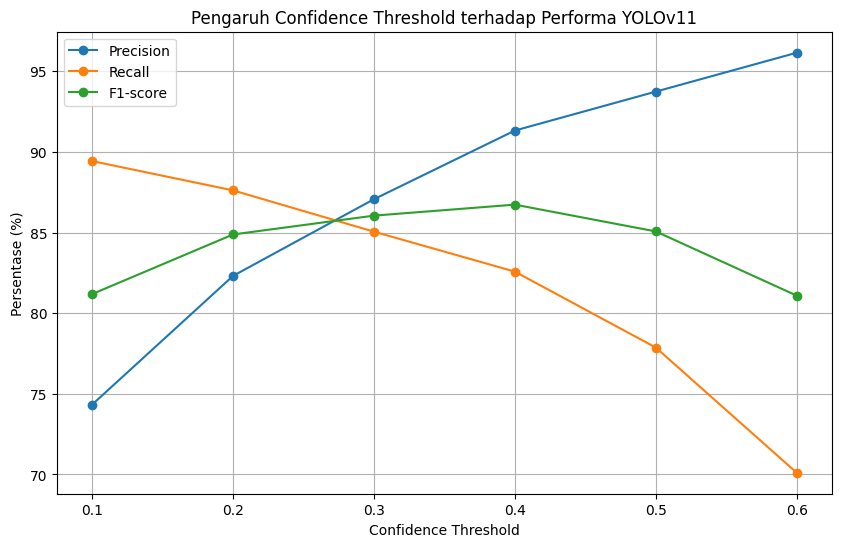

In [13]:
# Visualisasi Peforma
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    df_results["Confidence"],
    df_results["Precision (%)"],
    marker="o",
    label="Precision"
)

plt.plot(
    df_results["Confidence"],
    df_results["Recall (%)"],
    marker="o",
    label="Recall"
)

plt.plot(
    df_results["Confidence"],
    df_results["F1-score (%)"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Confidence Threshold")
plt.ylabel("Persentase (%)")
plt.title("Pengaruh Confidence Threshold terhadap Performa YOLOv11")
plt.xticks(CONF_THRESHOLDS)
plt.grid(True)
plt.legend()
plt.show()

Analisis Perubahan Peforma
(1) Precision meningkat ketika confidence dinaikkan
Semakin tinggi confidence threshold, semakin sedikit prediksi yang diterima model. Prediksi yang diterima cenderung lebih meyakinkan sehingga FP berkurang.
(2) Recall menurun ketika confidence dinaikkan
Ketika threshold semakin tinggi, semakin banyak objek sebenarnya yang tidak terdeteksi karena prediksinya tidak memenuhi batas confidence.
(3) F1-score tertinggi berada pada confidence 0.40
F1-score meningkat dari confidence 0.10 hingga 0.40, kemudian menurun pada confidence 0.50 dan 0.60. Ini menunjukkan bahwa confidence 0.40 memberikan keseimbangan Precision dan Recall terbaik di antara enam threshold yang diuji

Kesimpulan dan keputusan pengujian pada data test menggunakan confidence 0.40 dengan alasan peforma confusion matrix mencapai nilai tertinggi ketimbang lainnya.

Melakukan pengujian pada data test dengan ketentuan :
- Confidence >< 0.40
- NMS IoU >< 0.70
- Matching IoU >< 0.50
Tujuan : menghasilkan confusion matrix berupa precision, recall, f1-score, mAP

<Pengujian untuk menghasilkan mAP>

In [14]:
# Menyiapkan data test

# Konfigurasi pengujian akhir YOLOv11

TEST_IMAGE_DIR = Path(
    "/home/rzangef/spark-data/CHVG-YOLO/images/test"
)

TEST_LABEL_DIR = Path(
    "/home/rzangef/spark-data/CHVG-YOLO/labels/test"
)

DATA_YAML = "/home/rzangef/spark-data/CHVG-YOLO/data.yaml"

# Confidence hasil pengujian pendahuluan
TEST_CONF = 0.40

# Parameter pengujian
IMG_SIZE = 640
NMS_IOU = 0.70
MATCH_IOU = 0.50

# Folder penyimpanan hasil
TEST_OUTPUT_DIR = Path(
    "/home/rzangef/spark-data/yolo11_test_results"
)
TEST_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Mengambil daftar gambar test
test_images = sorted([
    p for p in TEST_IMAGE_DIR.rglob("*")
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
])

print("Jumlah gambar test:", len(test_images))
print("Confidence threshold:", TEST_CONF)
print("NMS IoU:", NMS_IOU)
print("Matching IoU:", MATCH_IOU)
print("Image size:", IMG_SIZE)

assert len(test_images) == 340, "Jumlah gambar test tidak sesuai!"
assert TEST_LABEL_DIR.is_dir(), "Folder anotasi test tidak ditemukan!"
assert Path(DATA_YAML).is_file(), "data.yaml tidak ditemukan!"

print("\nPersiapan pengujian test berhasil.")

Jumlah gambar test: 340
Confidence threshold: 0.4
NMS IoU: 0.7
Matching IoU: 0.5
Image size: 640

Persiapan pengujian test berhasil.


In [15]:

# ============================================================
# PENGUJIAN AKHIR YOLOv11 PADA DATA TEST
# Precision, Recall, F1-score, mAP, dan waktu pengujian
# ============================================================

# 1. Mulai pengukuran waktu
total_start = time.perf_counter()

# ------------------------------------------------------------
# 2. Evaluasi Precision, Recall, dan F1-score
# ------------------------------------------------------------

print("Memulai pengujian Precision, Recall, dan F1-score...")

metric_start = time.perf_counter()

total_tp = 0
total_fp = 0
total_fn = 0

for image_path in test_images:

    result = model.predict(
        source=str(image_path),
        imgsz=IMG_SIZE,
        conf=TEST_CONF,
        iou=NMS_IOU,
        device="cpu",
        verbose=False
    )[0]

    # Membaca anotasi ground truth
    label_path = (
        TEST_LABEL_DIR / image_path.relative_to(TEST_IMAGE_DIR)
    ).with_suffix(".txt")

    height, width = result.orig_shape

    gt_boxes, gt_classes = load_ground_truth(
        label_path, height, width
    )

    # Mengambil hasil prediksi
    if result.boxes is not None and len(result.boxes) > 0:
        pred_boxes = result.boxes.xyxy.cpu().numpy()
        pred_classes = result.boxes.cls.cpu().numpy().astype(int)
        pred_scores = result.boxes.conf.cpu().numpy()
    else:
        pred_boxes = np.empty((0, 4))
        pred_classes = np.array([], dtype=int)
        pred_scores = np.array([], dtype=float)

    # Menghitung TP, FP, FN
    tp, fp, fn = calculate_metrics_for_image(
        pred_boxes,
        pred_classes,
        pred_scores,
        gt_boxes,
        gt_classes,
        MATCH_IOU
    )

    total_tp += tp
    total_fp += fp
    total_fn += fn

# Menghitung metrik
precision = (
    total_tp / (total_tp + total_fp)
    if total_tp + total_fp > 0 else 0
)

recall = (
    total_tp / (total_tp + total_fn)
    if total_tp + total_fn > 0 else 0
)

f1_score = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0 else 0
)

metric_time = time.perf_counter() - metric_start

# ------------------------------------------------------------
# 3. Evaluasi mAP menggunakan evaluator Ultralytics
# ------------------------------------------------------------

print("\nMemulai evaluasi mAP...")

map_start = time.perf_counter()

metrics_test = model.val(
    data=DATA_YAML,
    split="test",
    imgsz=IMG_SIZE,
    batch=1,
    device="cpu",
    conf=0.001,
    iou=NMS_IOU,
    plots=True,
    project=str(TEST_OUTPUT_DIR),
    name="final_evaluation",
    exist_ok=True
)

map50 = metrics_test.box.map50
map5095 = metrics_test.box.map

map_time = time.perf_counter() - map_start

# ------------------------------------------------------------
# 4. Menghitung total waktu
# ------------------------------------------------------------

total_time = time.perf_counter() - total_start

# ------------------------------------------------------------
# 5. Menampilkan seluruh hasil pengujian
# ------------------------------------------------------------

final_results = pd.DataFrame([{
    "Confidence": TEST_CONF,
    "TP": total_tp,
    "FP": total_fp,
    "FN": total_fn,
    "Precision (%)": precision * 100,
    "Recall (%)": recall * 100,
    "F1-score (%)": f1_score * 100,
    "mAP@0.50 (%)": map50 * 100,
    "mAP@0.50:0.95 (%)": map5095 * 100,
    "Waktu metrik (detik)": metric_time,
    "Waktu mAP (detik)": map_time,
    "Total waktu (detik)": total_time
}])

print("\n==============================================")
print("       HASIL PENGUJIAN AKHIR YOLOv11")
print("==============================================")

display(final_results.round(2))

print("==============================================")
print(f"Total waktu pengujian: {total_time:.2f} detik")
print(f"Total waktu pengujian: {total_time / 60:.2f} menit")
print("==============================================")

# ------------------------------------------------------------
# 6. Menyimpan hasil ke CSV
# ------------------------------------------------------------

csv_path = TEST_OUTPUT_DIR / "hasil_pengujian_yolo_test.csv"

final_results.to_csv(csv_path, index=False)

print("\nHasil berhasil disimpan di:")
print(csv_path)

Memulai pengujian Precision, Recall, dan F1-score...

Memulai evaluasi mAP...
Ultralytics 8.4.157 🚀 Python-3.10.12 torch-2.14.0+cpu CPU (AMD Ryzen 7 7730U with Radeon Graphics)
YOLO11s summary (fused): 100 layers, 9,415,896 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1134.2±137.2 MB/s, size: 80.2 KB)
val: Scanning /home/rzangef/spark-data/CHVG-YOLO/labels/test.cache... 340 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 340/340 1.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 340/340 2.7it/s 2:080.3ss
                   all        340       2385      0.871      0.816      0.892       0.56
                person        338        964      0.899       0.86      0.917      0.602
                  vest        180        430      0.839      0.849      0.896      0.589
                yellow        142        247      0.884      0.939      0.937      0.612
                 

,Confidence,TP,FP,FN,Precision (%),Recall (%),F1-score (%),mAP@0.50 (%),mAP@0.50:0.95 (%),Waktu metrik (detik),Waktu mAP (detik),Total waktu (detik)
0,0.4,1955,202,430,90.64,81.97,86.09,89.21,56.03,111.83,135.33,247.16


Total waktu pengujian: 247.16 detik
Total waktu pengujian: 4.12 menit

Hasil berhasil disimpan di:
/home/rzangef/spark-data/yolo11_test_results/hasil_pengujian_yolo_test.csv


In [3]:
# Muat ulang file hasil_pengujian_yolo_test.csv
import pandas as pd

csv_path = TEST_OUTPUT_DIR / "hasil_pengujian_yolo_test.csv"

df_display = pd.read_csv(csv_path)

display(df_display)

,Confidence,TP,FP,FN,Precision (%),Recall (%),F1-score (%),mAP@0.50 (%),mAP@0.50:0.95 (%),Waktu metrik (detik),Waktu mAP (detik),Total waktu (detik)
0,0.4,1955,202,430,90.635141,81.97065,86.085425,89.211687,56.028604,111.825656,135.330972,247.157369


(2) Pengujian pada Data Test untuk menghasilkan Precision, Recall, F1-Score, mAP per class

In [11]:
# Fungsi perhitungan kelas
def calculate_metrics_per_class(
    pred_boxes,
    pred_classes,
    pred_scores,
    gt_boxes,
    gt_classes,
    match_iou,
    class_names
):
    # Menyiapkan penghitung untuk setiap kelas
    class_counts = {
        class_id: {"TP": 0, "FP": 0, "FN": 0}
        for class_id in range(len(class_names))
    }

    # Mengurutkan prediksi berdasarkan confidence tertinggi
    order = np.argsort(-pred_scores)

    matched_gt = set()

    # Mencocokkan setiap prediksi dengan ground truth
    for pred_idx in order:
        pred_box = pred_boxes[pred_idx]
        pred_class = int(pred_classes[pred_idx])

        candidates = [
            i for i, gt_class in enumerate(gt_classes)
            if int(gt_class) == pred_class and i not in matched_gt
        ]

        if len(candidates) == 0:
            class_counts[pred_class]["FP"] += 1
            continue

        ious = calculate_iou(pred_box, gt_boxes[candidates])

        best_position = np.argmax(ious)
        best_iou = ious[best_position]
        best_gt_idx = candidates[best_position]

        if best_iou >= match_iou:
            class_counts[pred_class]["TP"] += 1
            matched_gt.add(best_gt_idx)
        else:
            class_counts[pred_class]["FP"] += 1

    # Ground truth yang belum terdeteksi dihitung sebagai FN
    for gt_idx, gt_class in enumerate(gt_classes):
        if gt_idx not in matched_gt:
            class_counts[int(gt_class)]["FN"] += 1

    return class_counts

In [12]:
# Definisikan nama kelas
CLASS_NAMES = [
    "person",
    "vest",
    "yellow",
    "white",
    "glass",
    "blue",
    "red",
    "head"
]

print("Daftar kelas:", CLASS_NAMES)
print("Jumlah kelas:", len(CLASS_NAMES))

Daftar kelas: ['person', 'vest', 'yellow', 'white', 'glass', 'blue', 'red', 'head']
Jumlah kelas: 8


In [13]:
# Definisikan test_images
from pathlib import Path

TEST_IMAGE_DIR = Path("/home/rzangef/spark-data/CHVG-YOLO/images/test")
TEST_LABEL_DIR = Path("/home/rzangef/spark-data/CHVG-YOLO/labels/test")

test_images = sorted([
    p for p in TEST_IMAGE_DIR.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

print("Jumlah gambar test:", len(test_images))
print("Contoh gambar:", test_images[0] if test_images else "Tidak ditemukan")

Jumlah gambar test: 340
Contoh gambar: /home/rzangef/spark-data/CHVG-YOLO/images/test/000019_jpg.rf.549923f46def56cf8c294def971cc7d9.jpg


In [14]:
# Fungsi load_ground_truth()
def load_ground_truth(label_path, image_height, image_width):
    gt_boxes = []
    gt_classes = []

    if not label_path.exists():
        return np.array([]).reshape(0, 4), np.array([])

    with open(label_path, "r") as f:
        for line in f:
            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id, x_center, y_center, width, height = map(float, values)

            x_center *= image_width
            y_center *= image_height
            width *= image_width
            height *= image_height

            x1 = x_center - width / 2
            y1 = y_center - height / 2
            x2 = x_center + width / 2
            y2 = y_center + height / 2

            gt_boxes.append([x1, y1, x2, y2])
            gt_classes.append(int(class_id))

    return np.array(gt_boxes), np.array(gt_classes)

print(load_ground_truth)

<function load_ground_truth at 0x726f39966170>


In [15]:
# Import & Muat Model
from ultralytics import YOLO
MODEL_PATH = "/home/rzangef/spark-data/yolo11_runs/yolo11s_40epochs/weights/best.pt"
model = YOLO(MODEL_PATH)
print("Model YOLO berhasil dimuat!")

Model YOLO berhasil dimuat!


In [16]:
# Fungsi calculate_iou()
def calculate_iou(box, boxes):
    if len(boxes) == 0:
        return np.array([])

    x1 = np.maximum(box[0], boxes[:, 0])
    y1 = np.maximum(box[1], boxes[:, 1])
    x2 = np.minimum(box[2], boxes[:, 2])
    y2 = np.minimum(box[3], boxes[:, 3])

    intersection = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)

    box_area = (box[2] - box[0]) * (box[3] - box[1])
    boxes_area = (
        (boxes[:, 2] - boxes[:, 0]) *
        (boxes[:, 3] - boxes[:, 1])
    )

    union = box_area + boxes_area - intersection

    iou = intersection / np.maximum(union, 1e-7)

    return iou

In [17]:
print(calculate_iou)

<function calculate_iou at 0x726ef71a7520>


In [17]:
# Pengujian dan perhitungan metrik per class

import cv2
import time
import numpy as np
import pandas as pd

# Konfigurasi pengujian
TEST_CONF = 0.40
IMG_SIZE = 640
NMS_IOU = 0.70
MATCH_IOU = 0.50

# Inisialisasi penghitung setiap kelas
total_counts = {
    class_id: {"TP": 0, "FP": 0, "FN": 0}
    for class_id in range(len(CLASS_NAMES))
}

print("Jumlah gambar test:", len(test_images))

start_time = time.time()

# Prediksi seluruh gambar test
for image_path in test_images:

    image = cv2.imread(str(image_path))

    if image is None:
        print("Gambar gagal dibaca:", image_path)
        continue

    height, width = image.shape[:2]

    # Memuat anotasi ground truth
    label_path = TEST_LABEL_DIR / (image_path.stem + ".txt")

    gt_boxes, gt_classes = load_ground_truth(
        label_path, height, width
    )

    # Prediksi YOLO
    result = model.predict(
        source=str(image_path),
        imgsz=IMG_SIZE,
        conf=TEST_CONF,
        iou=NMS_IOU,
        device="cpu",
        verbose=False
    )[0]

    # Mengambil hasil prediksi
    if result.boxes is not None and len(result.boxes) > 0:
        pred_boxes = result.boxes.xyxy.cpu().numpy()
        pred_classes = result.boxes.cls.cpu().numpy().astype(int)
        pred_scores = result.boxes.conf.cpu().numpy()
    else:
        pred_boxes = np.empty((0, 4))
        pred_classes = np.array([], dtype=int)
        pred_scores = np.array([])

    # Menghitung TP, FP, FN per kelas
    image_counts = calculate_metrics_per_class(
        pred_boxes,
        pred_classes,
        pred_scores,
        gt_boxes,
        gt_classes,
        MATCH_IOU,
        CLASS_NAMES
    )

    # Mengakumulasi hasil
    for class_id in range(len(CLASS_NAMES)):
        for metric in ["TP", "FP", "FN"]:
            total_counts[class_id][metric] += image_counts[class_id][metric]

elapsed_time = time.time() - start_time

# Membuat tabel hasil per kelas
results_per_class = []

for class_id, class_name in enumerate(CLASS_NAMES):

    TP = total_counts[class_id]["TP"]
    FP = total_counts[class_id]["FP"]
    FN = total_counts[class_id]["FN"]

    precision = TP / (TP + FP) if TP + FP > 0 else 0
    recall = TP / (TP + FN) if TP + FN > 0 else 0

    f1_score = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    results_per_class.append({
        "Class": class_name,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1_score
    })

df_per_class = pd.DataFrame(results_per_class)


# ==========================================
# MENAMBAHKAN HASIL KESELURUHAN (ALL)
# ==========================================

# Menghitung total TP, FP, FN
total_TP = sum(total_counts[i]["TP"] for i in range(len(CLASS_NAMES)))
total_FP = sum(total_counts[i]["FP"] for i in range(len(CLASS_NAMES)))
total_FN = sum(total_counts[i]["FN"] for i in range(len(CLASS_NAMES)))

# Menghitung metrik keseluruhan
overall_precision = (
    total_TP / (total_TP + total_FP)
    if total_TP + total_FP > 0 else 0
)

overall_recall = (
    total_TP / (total_TP + total_FN)
    if total_TP + total_FN > 0 else 0
)

overall_f1 = (
    2 * overall_precision * overall_recall /
    (overall_precision + overall_recall)
    if overall_precision + overall_recall > 0 else 0
)

# Membuat baris ALL
all_row = {
    "Class": "all",
    "TP": total_TP,
    "FP": total_FP,
    "FN": total_FN,
    "Precision": overall_precision,
    "Recall": overall_recall,
    "F1-score": overall_f1
}

# Menambahkan ALL setelah kelas head
df_per_class = pd.concat(
    [df_per_class, pd.DataFrame([all_row])],
    ignore_index=True
)

# Mengubah nilai metrik menjadi persen
df_display = df_per_class.copy()

for metric in ["Precision", "Recall", "F1-score"]:
    df_display[metric] = (df_display[metric] * 100).round(2)

print("=== HASIL PENGUJIAN YOLOv11 ===")
display(df_display)

Jumlah gambar test: 340
=== HASIL PENGUJIAN YOLOv11 ===


,Class,TP,FP,FN,Precision,Recall,F1-score
0,person,806,66,158,92.43,83.61,87.80
1,vest,354,52,76,87.19,82.33,84.69
2,yellow,228,28,19,89.06,92.31,90.66
3,white,220,20,43,91.67,83.65,87.48
4,glass,57,13,46,81.43,55.34,65.90
5,blue,123,2,22,98.40,84.83,91.11
6,red,62,11,20,84.93,75.61,80.00
7,head,105,10,46,91.30,69.54,78.95
8,all,1955,202,430,90.64,81.97,86.09


In [18]:
# Pengujian dan perhitungan metrik per class part 2

import cv2
import time
import numpy as np
import pandas as pd

# ==========================================
# KONFIGURASI PENGUJIAN
# ==========================================

TEST_CONF = 0.40
IMG_SIZE = 640
NMS_IOU = 0.70
MATCH_IOU = 0.50

# Memastikan sumber data adalah folder test
print("Folder gambar:", TEST_IMAGE_DIR)
print("Folder label:", TEST_LABEL_DIR)
print("Jumlah gambar test:", len(test_images))

# ==========================================
# INISIALISASI PENGHITUNG SETIAP KELAS
# ==========================================

total_counts = {
    class_id: {"TP": 0, "FP": 0, "FN": 0}
    for class_id in range(len(CLASS_NAMES))
}

start_time = time.time()

# ==========================================
# PREDIKSI SELURUH GAMBAR TEST
# ==========================================

for image_path in test_images:

    image = cv2.imread(str(image_path))

    if image is None:
        print("Gambar gagal dibaca:", image_path)
        continue

    height, width = image.shape[:2]

    # Memuat anotasi ground truth
    label_path = TEST_LABEL_DIR / (image_path.stem + ".txt")

    gt_boxes, gt_classes = load_ground_truth(
        label_path, height, width
    )

    # Prediksi YOLO
    result = model.predict(
        source=str(image_path),
        imgsz=IMG_SIZE,
        conf=TEST_CONF,
        iou=NMS_IOU,
        device="cpu",
        verbose=False
    )[0]

    # Mengambil hasil prediksi
    if result.boxes is not None and len(result.boxes) > 0:
        pred_boxes = result.boxes.xyxy.cpu().numpy()
        pred_classes = result.boxes.cls.cpu().numpy().astype(int)
        pred_scores = result.boxes.conf.cpu().numpy()
    else:
        pred_boxes = np.empty((0, 4))
        pred_classes = np.array([], dtype=int)
        pred_scores = np.array([])

    # Menghitung TP, FP, FN per kelas
    image_counts = calculate_metrics_per_class(
        pred_boxes,
        pred_classes,
        pred_scores,
        gt_boxes,
        gt_classes,
        MATCH_IOU,
        CLASS_NAMES
    )

    # Mengakumulasi hasil
    for class_id in range(len(CLASS_NAMES)):
        for metric in ["TP", "FP", "FN"]:
            total_counts[class_id][metric] += image_counts[class_id][metric]

elapsed_time = time.time() - start_time

# ==========================================
# MEMBUAT TABEL HASIL PER KELAS
# ==========================================

results_per_class = []

for class_id, class_name in enumerate(CLASS_NAMES):

    TP = total_counts[class_id]["TP"]
    FP = total_counts[class_id]["FP"]
    FN = total_counts[class_id]["FN"]

    precision = TP / (TP + FP) if TP + FP > 0 else 0
    recall = TP / (TP + FN) if TP + FN > 0 else 0

    f1_score = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    results_per_class.append({
        "Class": class_name,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1_score
    })

df_per_class = pd.DataFrame(results_per_class)

# ==========================================
# MENAMBAHKAN HASIL KESELURUHAN (ALL)
# ==========================================

total_TP = sum(total_counts[i]["TP"] for i in range(len(CLASS_NAMES)))
total_FP = sum(total_counts[i]["FP"] for i in range(len(CLASS_NAMES)))
total_FN = sum(total_counts[i]["FN"] for i in range(len(CLASS_NAMES)))

overall_precision = (
    total_TP / (total_TP + total_FP)
    if total_TP + total_FP > 0 else 0
)

overall_recall = (
    total_TP / (total_TP + total_FN)
    if total_TP + total_FN > 0 else 0
)

overall_f1 = (
    2 * overall_precision * overall_recall /
    (overall_precision + overall_recall)
    if overall_precision + overall_recall > 0 else 0
)

all_row = {
    "Class": "all",
    "TP": total_TP,
    "FP": total_FP,
    "FN": total_FN,
    "Precision": overall_precision,
    "Recall": overall_recall,
    "F1-score": overall_f1
}

df_per_class = pd.concat(
    [df_per_class, pd.DataFrame([all_row])],
    ignore_index=True
)

# ==========================================
# MENGUBAH NILAI METRIK MENJADI PERSEN
# ==========================================

df_display = df_per_class.copy()

for metric in ["Precision", "Recall", "F1-score"]:
    df_display[metric] = (df_display[metric] * 100).round(2)

# ==========================================
# MENYIMPAN HASIL KE CSV
# ==========================================

OUTPUT_CSV = TEST_OUTPUT_DIR / "hasil_evaluasi_per_class_test.csv"

df_display.to_csv(
    OUTPUT_CSV,
    index=False
)

# ==========================================
# MENAMPILKAN HASIL
# ==========================================

print("\n=== HASIL PENGUJIAN YOLOv11 DATA TEST ===")
display(df_display)

print("\nWaktu pengujian:", round(elapsed_time, 2), "detik")
print("Hasil CSV berhasil disimpan di:")
print(OUTPUT_CSV)

Folder gambar: /home/rzangef/spark-data/CHVG-YOLO/images/test
Folder label: /home/rzangef/spark-data/CHVG-YOLO/labels/test
Jumlah gambar test: 340

=== HASIL PENGUJIAN YOLOv11 DATA TEST ===


,Class,TP,FP,FN,Precision,Recall,F1-score
0,person,806,66,158,92.43,83.61,87.80
1,vest,354,52,76,87.19,82.33,84.69
2,yellow,228,28,19,89.06,92.31,90.66
3,white,220,20,43,91.67,83.65,87.48
4,glass,57,13,46,81.43,55.34,65.90
5,blue,123,2,22,98.40,84.83,91.11
6,red,62,11,20,84.93,75.61,80.00
7,head,105,10,46,91.30,69.54,78.95
8,all,1955,202,430,90.64,81.97,86.09



Waktu pengujian: 134.66 detik
Hasil CSV berhasil disimpan di:
/home/rzangef/spark-data/yolo11_test_results/hasil_evaluasi_per_class_test.csv


(3) Visualisasi Hasil Pengujian

In [19]:
# Persiapan Data
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Membaca hasil evaluasi data test
CSV_PATH = TEST_OUTPUT_DIR / "hasil_evaluasi_per_class_test.csv"

df_visual = pd.read_csv(CSV_PATH)

# Memisahkan kelas dan baris all
df_class = df_visual[df_visual["Class"] != "all"].copy()

print("Data yang akan divisualisasikan:")
display(df_class)

Data yang akan divisualisasikan:


,Class,TP,FP,FN,Precision,Recall,F1-score
0,person,806,66,158,92.43,83.61,87.80
1,vest,354,52,76,87.19,82.33,84.69
2,yellow,228,28,19,89.06,92.31,90.66
3,white,220,20,43,91.67,83.65,87.48
4,glass,57,13,46,81.43,55.34,65.90
5,blue,123,2,22,98.40,84.83,91.11
6,red,62,11,20,84.93,75.61,80.00
7,head,105,10,46,91.30,69.54,78.95


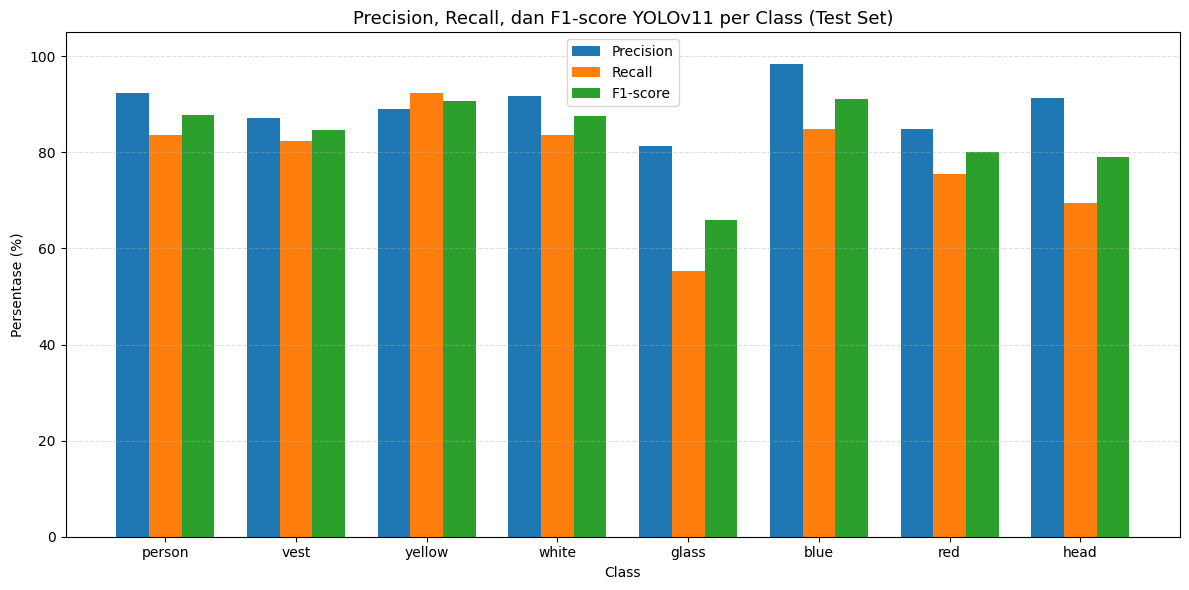

In [20]:
# Menyiapkan data
classes = df_class["Class"]

x = np.arange(len(classes))
width = 0.25

# Membuat grafik
fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    x - width,
    df_class["Precision"],
    width,
    label="Precision"
)

ax.bar(
    x,
    df_class["Recall"],
    width,
    label="Recall"
)

ax.bar(
    x + width,
    df_class["F1-score"],
    width,
    label="F1-score"
)

# Pengaturan grafik
ax.set_title(
    "Precision, Recall, dan F1-score YOLOv11 per Class (Test Set)",
    fontsize=13
)

ax.set_xlabel("Class")
ax.set_ylabel("Persentase (%)")

ax.set_xticks(x)
ax.set_xticklabels(classes)

ax.set_ylim(0, 105)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

# Menyimpan grafik
plt.savefig(
    TEST_OUTPUT_DIR / "visualisasi_metrik_per_class_test.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

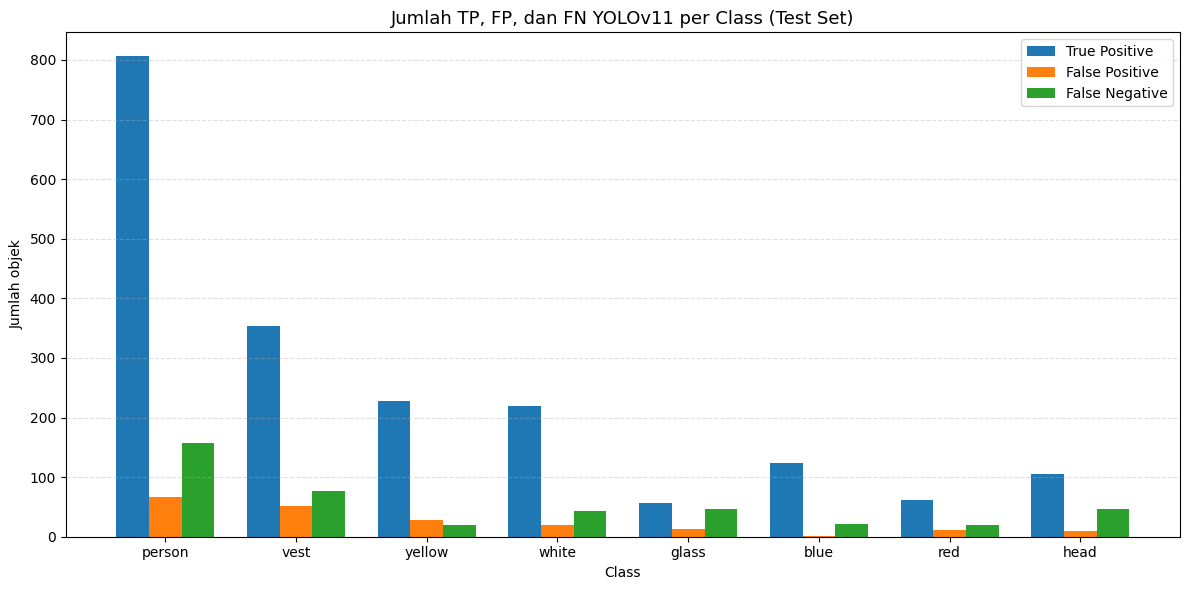

In [21]:
# Visualisasi TP, FP, FN per class
# Menyiapkan data
x = np.arange(len(classes))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    x - width,
    df_class["TP"],
    width,
    label="True Positive"
)

ax.bar(
    x,
    df_class["FP"],
    width,
    label="False Positive"
)

ax.bar(
    x + width,
    df_class["FN"],
    width,
    label="False Negative"
)

# Pengaturan grafik
ax.set_title(
    "Jumlah TP, FP, dan FN YOLOv11 per Class (Test Set)",
    fontsize=13
)

ax.set_xlabel("Class")
ax.set_ylabel("Jumlah objek")

ax.set_xticks(x)
ax.set_xticklabels(classes)

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

# Menyimpan grafik
plt.savefig(
    TEST_OUTPUT_DIR / "visualisasi_TP_FP_FN_per_class_test.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

(4) Mengukur Kecepatan Deteksi / Inference Speed
Tujuan : mengetahui berapa lama model YOLOv11 membutuhkan waktu untuk memproses sebuah gambar dan menghasilkan prediksi

In [22]:
# Warm-Up model menggunakan satu gambar test
warmup_result = model.predict(
    source=str(test_images[0]),
    imgsz=640,
    conf=0.40,
    iou=0.70,
    device="cpu",
    verbose=False
)

print("Warm-up YOLOv11 berhasil!")

Warm-up YOLOv11 berhasil!


In [ ]:
# Mengukur kecepatan deteksi pada 340 gambar
import numpy as np
import pandas as pd

# Konfigurasi pengujian
IMG_SIZE = 640
TEST_CONF = 0.40
NMS_IOU = 0.70
REPEAT = 3

# Menyimpan hasil pengukuran
speed_results = []

for run in range(1, REPEAT + 1):

    print(f"Menjalankan pengujian ke-{run}...")

    results = model.predict(
        source=[str(p) for p in test_images],
        imgsz=IMG_SIZE,
        conf=TEST_CONF,
        iou=NMS_IOU,
        device="cpu",
        batch=1,
        stream=True,
        verbose=False
    )

    preprocess_times = []
    inference_times = []
    postprocess_times = []

    processed_images = 0

    for result in results:

        preprocess_times.append(result.speed["preprocess"])
        inference_times.append(result.speed["inference"])
        postprocess_times.append(result.speed["postprocess"])

        processed_images += 1

    # Menghitung rata-rata waktu (ms/gambar)
    avg_preprocess = np.mean(preprocess_times)
    avg_inference = np.mean(inference_times)
    avg_postprocess = np.mean(postprocess_times)

    avg_total = (
        avg_preprocess +
        avg_inference +
        avg_postprocess
    )

    # Menghitung FPS berdasarkan total waktu
    fps = 1000 / avg_total

    speed_results.append({
        "Pengujian": run,
        "Jumlah Gambar": processed_images,
        "Preprocess (ms)": avg_preprocess,
        "Inference (ms)": avg_inference,
        "Postprocess (ms)": avg_postprocess,
        "Total (ms)": avg_total,
        "FPS": fps
    })

    print(f"Pengujian ke-{run} selesai: {processed_images} gambar")

# Membuat tabel hasil
df_speed = pd.DataFrame(speed_results)

display(df_speed.round(3))

Menjalankan pengujian ke-1...


Menjalankan langsung 340 gambar menyebabkan RAM menyentuh titik tertinggi yaitu 14,6 dari 15,4 sehingga harus restart kernel

In [1]:
print("Kernel aktif dan siap digunakan!")

Kernel aktif dan siap digunakan!


In [2]:
# Memuat Model
from ultralytics import YOLO
import numpy as np
import pandas as pd
import time
from pathlib import Path

# Lokasi model terbaik
MODEL_PATH = "/home/rzangef/spark-data/yolo11_runs/yolo11s_40epochs/weights/best.pt"

# Memuat model
model = YOLO(MODEL_PATH)

print("Model YOLOv11 berhasil dimuat!")

Model YOLOv11 berhasil dimuat!


In [3]:
# Mendefinisikan folder gambar test
TEST_IMAGE_DIR = Path("/home/rzangef/spark-data/CHVG-YOLO/images/test")

test_images = sorted([
    p for p in TEST_IMAGE_DIR.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

print("Jumlah gambar test:", len(test_images))

Jumlah gambar test: 340


In [4]:
# Menentukan konfigurasi pengujian
IMG_SIZE = 640
TEST_CONF = 0.40
NMS_IOU = 0.70
REPEAT = 3

print("Konfigurasi pengujian:")
print("Image size:", IMG_SIZE)
print("Confidence threshold:", TEST_CONF)
print("NMS IoU:", NMS_IOU)
print("Jumlah pengulangan:", REPEAT)

Konfigurasi pengujian:
Image size: 640
Confidence threshold: 0.4
NMS IoU: 0.7
Jumlah pengulangan: 3


In [5]:
# Warm up
warmup_result = model.predict(
    source=str(test_images[0]),
    imgsz=IMG_SIZE,
    conf=TEST_CONF,
    iou=NMS_IOU,
    device="cpu",
    verbose=False
)

print("Warm-up berhasil!")

Warm-up berhasil!


In [6]:
# Uji coba dengan 20 gambar
test_speed_20 = []

for i, image_path in enumerate(test_images[:20], start=1):

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.40,
        iou=0.70,
        device="cpu",
        verbose=False
    )[0]

    test_speed_20.append(result.speed["inference"])

    del result

    print(f"{i}/20 gambar selesai")

print("\nRata-rata inference time:",
      round(np.mean(test_speed_20), 3), "ms/gambar")

1/20 gambar selesai
2/20 gambar selesai
3/20 gambar selesai
4/20 gambar selesai
5/20 gambar selesai
6/20 gambar selesai
7/20 gambar selesai
8/20 gambar selesai
9/20 gambar selesai
10/20 gambar selesai
11/20 gambar selesai
12/20 gambar selesai
13/20 gambar selesai
14/20 gambar selesai
15/20 gambar selesai
16/20 gambar selesai
17/20 gambar selesai
18/20 gambar selesai
19/20 gambar selesai
20/20 gambar selesai

Rata-rata inference time: 362.067 ms/gambar


In [7]:
# Pengujian ke-1
preprocess_times_1 = []
inference_times_1 = []
postprocess_times_1 = []

for i, image_path in enumerate(test_images, start=1):

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.40,
        iou=0.70,
        device="cpu",
        verbose=False
    )[0]

    preprocess_times_1.append(result.speed["preprocess"])
    inference_times_1.append(result.speed["inference"])
    postprocess_times_1.append(result.speed["postprocess"])

    del result

    if i % 20 == 0:
        print(f"Pengujian 1: {i}/340 gambar selesai")

# Menghitung rata-rata waktu
avg_preprocess_1 = np.mean(preprocess_times_1)
avg_inference_1 = np.mean(inference_times_1)
avg_postprocess_1 = np.mean(postprocess_times_1)

avg_total_1 = (
    avg_preprocess_1 +
    avg_inference_1 +
    avg_postprocess_1
)

fps_1 = 1000 / avg_total_1

print("\nHASIL PENGUJIAN KE-1")
print("Preprocess:", round(avg_preprocess_1, 3), "ms")
print("Inference:", round(avg_inference_1, 3), "ms")
print("Postprocess:", round(avg_postprocess_1, 3), "ms")
print("Total:", round(avg_total_1, 3), "ms")
print("FPS:", round(fps_1, 3))

Pengujian 1: 20/340 gambar selesai
Pengujian 1: 40/340 gambar selesai
Pengujian 1: 60/340 gambar selesai
Pengujian 1: 80/340 gambar selesai
Pengujian 1: 100/340 gambar selesai
Pengujian 1: 120/340 gambar selesai
Pengujian 1: 140/340 gambar selesai
Pengujian 1: 160/340 gambar selesai
Pengujian 1: 180/340 gambar selesai
Pengujian 1: 200/340 gambar selesai
Pengujian 1: 220/340 gambar selesai
Pengujian 1: 240/340 gambar selesai
Pengujian 1: 260/340 gambar selesai
Pengujian 1: 280/340 gambar selesai
Pengujian 1: 300/340 gambar selesai
Pengujian 1: 320/340 gambar selesai
Pengujian 1: 340/340 gambar selesai

HASIL PENGUJIAN KE-1
Preprocess: 5.544 ms
Inference: 361.344 ms
Postprocess: 1.297 ms
Total: 368.185 ms
FPS: 2.716


In [8]:
# Pengujian Ke-2
preprocess_times_2 = []
inference_times_2 = []
postprocess_times_2 = []

for i, image_path in enumerate(test_images, start=1):

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.40,
        iou=0.70,
        device="cpu",
        verbose=False
    )[0]

    preprocess_times_2.append(result.speed["preprocess"])
    inference_times_2.append(result.speed["inference"])
    postprocess_times_2.append(result.speed["postprocess"])

    del result

    if i % 20 == 0:
        print(f"Pengujian 2: {i}/340 gambar selesai")

avg_preprocess_2 = np.mean(preprocess_times_2)
avg_inference_2 = np.mean(inference_times_2)
avg_postprocess_2 = np.mean(postprocess_times_2)

avg_total_2 = (
    avg_preprocess_2 +
    avg_inference_2 +
    avg_postprocess_2
)

fps_2 = 1000 / avg_total_2

print("\nHASIL PENGUJIAN KE-2")
print("Preprocess:", round(avg_preprocess_2, 3), "ms")
print("Inference:", round(avg_inference_2, 3), "ms")
print("Postprocess:", round(avg_postprocess_2, 3), "ms")
print("Total:", round(avg_total_2, 3), "ms")
print("FPS:", round(fps_2, 3))

Pengujian 2: 20/340 gambar selesai
Pengujian 2: 40/340 gambar selesai
Pengujian 2: 60/340 gambar selesai
Pengujian 2: 80/340 gambar selesai
Pengujian 2: 100/340 gambar selesai
Pengujian 2: 120/340 gambar selesai
Pengujian 2: 140/340 gambar selesai
Pengujian 2: 160/340 gambar selesai
Pengujian 2: 180/340 gambar selesai
Pengujian 2: 200/340 gambar selesai
Pengujian 2: 220/340 gambar selesai
Pengujian 2: 240/340 gambar selesai
Pengujian 2: 260/340 gambar selesai
Pengujian 2: 280/340 gambar selesai
Pengujian 2: 300/340 gambar selesai
Pengujian 2: 320/340 gambar selesai
Pengujian 2: 340/340 gambar selesai

HASIL PENGUJIAN KE-2
Preprocess: 5.439 ms
Inference: 359.505 ms
Postprocess: 1.285 ms
Total: 366.229 ms
FPS: 2.731


In [9]:
# Pengujian ke-3
preprocess_times_3 = []
inference_times_3 = []
postprocess_times_3 = []

for i, image_path in enumerate(test_images, start=1):

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.40,
        iou=0.70,
        device="cpu",
        verbose=False
    )[0]

    preprocess_times_3.append(result.speed["preprocess"])
    inference_times_3.append(result.speed["inference"])
    postprocess_times_3.append(result.speed["postprocess"])

    del result

    if i % 20 == 0:
        print(f"Pengujian 3: {i}/340 gambar selesai")

avg_preprocess_3 = np.mean(preprocess_times_3)
avg_inference_3 = np.mean(inference_times_3)
avg_postprocess_3 = np.mean(postprocess_times_3)

avg_total_3 = (
    avg_preprocess_3 +
    avg_inference_3 +
    avg_postprocess_3
)

fps_3 = 1000 / avg_total_3

print("\nHASIL PENGUJIAN KE-3")
print("Preprocess:", round(avg_preprocess_3, 3), "ms")
print("Inference:", round(avg_inference_3, 3), "ms")
print("Postprocess:", round(avg_postprocess_3, 3), "ms")
print("Total:", round(avg_total_3, 3), "ms")
print("FPS:", round(fps_3, 3))

Pengujian 3: 20/340 gambar selesai
Pengujian 3: 40/340 gambar selesai
Pengujian 3: 60/340 gambar selesai
Pengujian 3: 80/340 gambar selesai
Pengujian 3: 100/340 gambar selesai
Pengujian 3: 120/340 gambar selesai
Pengujian 3: 140/340 gambar selesai
Pengujian 3: 160/340 gambar selesai
Pengujian 3: 180/340 gambar selesai
Pengujian 3: 200/340 gambar selesai
Pengujian 3: 220/340 gambar selesai
Pengujian 3: 240/340 gambar selesai
Pengujian 3: 260/340 gambar selesai
Pengujian 3: 280/340 gambar selesai
Pengujian 3: 300/340 gambar selesai
Pengujian 3: 320/340 gambar selesai
Pengujian 3: 340/340 gambar selesai

HASIL PENGUJIAN KE-3
Preprocess: 5.905 ms
Inference: 359.59 ms
Postprocess: 1.306 ms
Total: 366.8 ms
FPS: 2.726


In [10]:
# Hasil
df_speed = pd.DataFrame([
    {
        "Pengujian": 1,
        "Preprocess (ms)": avg_preprocess_1,
        "Inference (ms)": avg_inference_1,
        "Postprocess (ms)": avg_postprocess_1,
        "Total (ms)": avg_total_1,
        "FPS": fps_1
    },
    {
        "Pengujian": 2,
        "Preprocess (ms)": avg_preprocess_2,
        "Inference (ms)": avg_inference_2,
        "Postprocess (ms)": avg_postprocess_2,
        "Total (ms)": avg_total_2,
        "FPS": fps_2
    },
    {
        "Pengujian": 3,
        "Preprocess (ms)": avg_preprocess_3,
        "Inference (ms)": avg_inference_3,
        "Postprocess (ms)": avg_postprocess_3,
        "Total (ms)": avg_total_3,
        "FPS": fps_3
    }
])

display(df_speed.round(3))

,Pengujian,Preprocess (ms),Inference (ms),Postprocess (ms),Total (ms),FPS
0,1,5.544,361.344,1.297,368.185,2.716
1,2,5.439,359.505,1.285,366.229,2.731
2,3,5.905,359.590,1.306,366.800,2.726


In [11]:
print("RATA-RATA 3 PENGUJIAN")

print("Preprocess:", round(df_speed["Preprocess (ms)"].mean(), 3), "ms")
print("Inference:", round(df_speed["Inference (ms)"].mean(), 3), "ms")
print("Postprocess:", round(df_speed["Postprocess (ms)"].mean(), 3), "ms")
print("Total:", round(df_speed["Total (ms)"].mean(), 3), "ms")
print("FPS:", round(1000 / df_speed["Total (ms)"].mean(), 3))

RATA-RATA 3 PENGUJIAN
Preprocess: 5.629 ms
Inference: 360.146 ms
Postprocess: 1.296 ms
Total: 367.071 ms
FPS: 2.724


In [12]:
# Simpan hasil
df_speed.to_csv("hasil_kecepatan_yolov11.csv", index=False)
print("Tabel hasil pengukuran berhasil disimpan.")

Tabel hasil pengukuran berhasil disimpan.


In [13]:
# Cek lokasi
import os
print(os.getcwd())

/home/rzangef/implementasi-model/yolo_fix


Catatan
- Preprocessing : waktu untuk mempersiapkan gambar sebelum masuk ke model
- Inference : waktu yang digunakan YOLOv11 untuk melakukan proses inferensi
- Postprocessing : waktu untuk memproses hasil prediksi, termasuk NMS

(5) Mengukur Ukuran Model
Tujuan : mengukur kebutuhan ruang penyimpanan model untuk mempertimbangkan efisiensi ketika model akan didistribusikan atau diterapkan pada perangkat dengan kapasitas penyimpanan terbatas

In [14]:
# Mengukur ukuran file model
from pathlib import Path

# Lokasi model YOLOv11 hasil training
MODEL_PATH = Path(
    "/home/rzangef/spark-data/yolo11_runs/yolo11s_40epochs/weights/best.pt"
)

# Mengukur ukuran file dalam byte
size_bytes = MODEL_PATH.stat().st_size

# Mengonversi ukuran ke MB
size_mb = size_bytes / (1024 * 1024)

print("=== UKURAN MODEL YOLOv11 ===")
print(f"Nama file  : {MODEL_PATH.name}")
print(f"Ukuran     : {size_mb:.2f} MB")
print(f"Ukuran byte: {size_bytes:,} bytes")

=== UKURAN MODEL YOLOv11 ===
Nama file  : best.pt
Ukuran     : 18.29 MB
Ukuran byte: 19,181,466 bytes
